
# Paper-Reconstruction Baselines vs. MicroBrainNet-DA v7
### AgroNet / TL model / Baseline (Kimutai & Förster, GoodIT '24) — same PlantVillage→PlantDoc setup

This is a **standalone comparison notebook**. It does **not** import anything from your
`microbrainnet-da-plantdisease-v8-fixed.ipynb` at runtime — instead it **re-implements the exact
same data indexing and split code** (same paths, same 3 classes, same seed, same 70/15/15
stratified split) so that, run in the same environment (same Kaggle dataset mounts), it produces
**bit-for-bit identical train/val/test image sets**. That is the only way a comparison between
the two notebooks is actually fair — different random splits, even with the same seed, are not
guaranteed to line up unless the indexing code itself is identical.

**Setup (matches your MicroBrainNet-DA notebook exactly):**

| | Source domain | Target domain |
|---|---|---|
| Dataset | PlantVillage (`color/`) | PlantDoc |
| Classes | `Tomato_Septoria_Leaf_Spot`, `Potato_Early_Blight`, `Corn_Leaf_Blight` | **same 3 classes** |
| Nature | lab photos, uniform background | field photos, cluttered background |

So this is **pure domain shift** (same task, same classes, different distribution) — exactly
Figure 1 of the paper, and exactly your MicroBrainNet-DA setup. No class-head-swapping is needed
anywhere below, since both domains share the same 3 labels.

**What's implemented, mirroring the paper as closely as possible:**

- **AgroNet** = TeaNet-style backbone (trained from scratch) + a domain-classification head via a
  Gradient Reversal Layer (Table 1: "Domain: Fully Connected Layer (output)")
- **Baseline** = frozen pre-trained CNN backbone + a single task-specific FC layer (Table 1)
- **TL model** = pre-trained CNN backbone + **gradual fine-tuning** (Table 1)
- Target retraining follows the paper's own protocol: **max(10% of target-train, 10 images per
  class)** (Section 4.2 / 5.2) — but the retrain pool is drawn only from `tgt_train`, and the
  held-out `tgt_test` split is **never touched until the final, single evaluation pass** — same
  discipline as your notebook's FIX #13 (no test-set peeking).
- **Bootstrap 95% CI** on target-test accuracy — copied from your own `bootstrap_ci()` — so the
  three paper baselines and MicroBrainNet-DA are reported with the same rigor.
- Memory/energy measurement (Table 2 style), **parameter count / model size** (fp32 and an
  estimated int8 size, comparable to MicroBrainNet-DA's `deploy_params`), and a final **combined
  comparison table + plot** where you paste in MicroBrainNet-DA's own numbers from its Part 11 /
  Part 7 output.

> **Run this in the same environment (e.g. the same Kaggle notebook session/dataset mounts) as
> your MicroBrainNet-DA notebook.** If the two are run on different machines/filesystems, the
> `os.walk` traversal order could in principle differ, which could produce a different (though
> equally-sized) split even with the same seed — see the caveat at the very end.



## 0. Setup


In [1]:

import os, sys, time, copy, random, json, math
from collections import OrderedDict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_score, f1_score, accuracy_score

import psutil
from PIL import Image

SEED = 42

def set_seed(s):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE} | PyTorch: {torch.__version__}")

OUTPUT_DIR = "./paper_baselines_output"
FIGURES_DIR = f"{OUTPUT_DIR}/figures"
TABLES_DIR  = f"{OUTPUT_DIR}/tables"
for d in [FIGURES_DIR, TABLES_DIR]:
    os.makedirs(d, exist_ok=True)


Device: cuda | PyTorch: 2.11.0+cu128



## 1. Configuration — identical paths/classes to your MicroBrainNet-DA notebook

**Copied verbatim** from your Part 0 / Part 1A. Do not change `CLASSES`, `SOURCE_CLASS_DIRS`,
`TARGET_CLASS_DIRS`, or `SEED` — those four must stay byte-identical to your other notebook for
the splits to line up.


In [2]:

SOURCE_ALL = "/kaggle/input/datasets/abdallahalidev/plantvillage-dataset/color"
TARGET_ALL = "/kaggle/input/datasets/nirmalsankalana/plantdoc-dataset"

CLASSES = ["Tomato_Septoria_Leaf_Spot", "Potato_Early_Blight", "Corn_Leaf_Blight"]

SOURCE_CLASS_DIRS = {
    "Tomato_Septoria_Leaf_Spot": ["Tomato___Septoria_leaf_spot"],
    "Potato_Early_Blight":       ["Potato___Early_blight"],
    "Corn_Leaf_Blight":          ["Corn_(maize)___Northern_Leaf_Blight"],
}
TARGET_CLASS_DIRS = {
    "Tomato_Septoria_Leaf_Spot": ["Tomato Septoria leaf spot"],
    "Potato_Early_Blight":       ["Potato leaf early blight"],
    "Corn_Leaf_Blight":          ["Corn leaf blight"],
}

NUM_CLASSES = len(CLASSES)

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

# --- paper-side hyperparameters (Sections 4.3 / 5.2, Table 1) ---
CONFIG = {
    "AGRONET_IMG_SIZE": 128,     # TeaNet trained from scratch -> small, TinyML-appropriate
    "PRETRAINED_IMG_SIZE": 224,  # Baseline/TL use an ImageNet-pretrained backbone -> needs 224
    "BATCH_SIZE": 16,
    "EPOCHS_SOURCE": 30,          # paper: 30 epochs, Fig. 5
    "EPOCHS_TARGET": 30,
    "LR": 1e-3,
    "TARGET_RETRAIN_FRACTION": 0.10,     # paper: "10% of the data in the target domain"
    "TARGET_MIN_IMAGES_PER_CLASS": 10,   # paper: "and 10 images in each class"
    "DOMAIN_ADV_LAMBDA": 0.3,
    "ASSUMED_POWER_W": 15.0,     # set to your machine's approx. wattage for the energy estimate
}



## 2. Data indexing & split — copied verbatim from your notebook (Part 1A)

`LeafIndex` and `stratified_split_indices` are reproduced **exactly** (same alias-matching logic,
same `train_test_split` calls, same `val_frac=0.15`/`test_frac=0.15`, same `SEED`). Given the
same filesystem layout, this reproduces your `src_train_idx / src_val_idx / src_test_idx /
tgt_train_idx / tgt_val_idx / tgt_test_idx` exactly.


In [3]:

class LeafIndex:
    '''Path/label index only -- no transforms. Walks root_dir recursively and pools
    every image under any folder whose normalized name matches an alias for a class.'''

    def __init__(self, root_dir, classes, class_dir_map, domain_label=0, name=""):
        self.img_paths, self.labels = [], []
        self.classes, self.domain_label = classes, domain_label

        def _norm(s):
            return s.strip().lower().replace(" ", "").replace("_", "")

        for idx, cls in enumerate(classes):
            alias = {_norm(a) for a in class_dir_map.get(cls, [cls])}
            matched = [dp for dp, _, _ in os.walk(root_dir) if _norm(os.path.basename(dp)) in alias]
            for d in matched:
                for f in sorted(os.listdir(d)):
                    if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp')):
                        self.img_paths.append(os.path.join(d, f)); self.labels.append(idx)
            if not matched:
                print(f"    WARNING: no folder matched '{cls}' under {root_dir}")

        print(f"  [{name}] {len(self.img_paths)} images")
        for i, c in enumerate(classes):
            print(f"    {c}: {self.labels.count(i)}")

    def subset(self, indices):
        s = copy.copy(self)
        s.img_paths = [self.img_paths[i] for i in indices]
        s.labels    = [self.labels[i] for i in indices]
        return s


def stratified_split_indices(labels, val_frac=0.15, test_frac=0.15, seed=SEED):
    idx_all = list(range(len(labels)))
    idx_tv, idx_test = train_test_split(idx_all, test_size=test_frac, stratify=labels,
                                        random_state=seed)
    lab_tv = [labels[i] for i in idx_tv]
    idx_tr, idx_val = train_test_split(idx_tv, test_size=val_frac / (1 - test_frac),
                                       stratify=lab_tv, random_state=seed)
    return idx_tr, idx_val, idx_test


for nm, p in [('PlantVillage color', SOURCE_ALL), ('PlantDoc', TARGET_ALL)]:
    print(f"  {nm:24s}: {'OK ' if os.path.isdir(p) else '!! NOT FOUND !!'} {p}")

print("\n--- Source (PlantVillage) ---")
src_index = LeafIndex(SOURCE_ALL, CLASSES, SOURCE_CLASS_DIRS, 0, "Source")
print("\n--- Target (PlantDoc) ---")
tgt_index = LeafIndex(TARGET_ALL, CLASSES, TARGET_CLASS_DIRS, 1, "Target")

src_tr_i, src_va_i, src_te_i = stratified_split_indices(src_index.labels)
tgt_tr_i, tgt_va_i, tgt_te_i = stratified_split_indices(tgt_index.labels)

src_train_idx = src_index.subset(src_tr_i)
src_val_idx   = src_index.subset(src_va_i)
src_test_idx  = src_index.subset(src_te_i)
tgt_train_idx = tgt_index.subset(tgt_tr_i)
tgt_val_idx   = tgt_index.subset(tgt_va_i)
tgt_test_idx  = tgt_index.subset(tgt_te_i)

print(f"\nSource  train/val/test: {len(src_train_idx.labels)}/"
      f"{len(src_val_idx.labels)}/{len(src_test_idx.labels)}")
print(f"Target  train/val/test: {len(tgt_train_idx.labels)}/"
      f"{len(tgt_val_idx.labels)}/{len(tgt_test_idx.labels)}")
print(f"\nNOTE: target test = {len(tgt_test_idx.labels)} images -> 1 image = "
      f"{100/len(tgt_test_idx.labels):.2f} accuracy points. Report the bootstrap CI, not a bare point estimate.")


  PlantVillage color      : OK  /kaggle/input/datasets/abdallahalidev/plantvillage-dataset/color
  PlantDoc                : OK  /kaggle/input/datasets/nirmalsankalana/plantdoc-dataset

--- Source (PlantVillage) ---
  [Source] 3756 images
    Tomato_Septoria_Leaf_Spot: 1771
    Potato_Early_Blight: 1000
    Corn_Leaf_Blight: 985

--- Target (PlantDoc) ---
  [Target] 522 images
    Tomato_Septoria_Leaf_Spot: 157
    Potato_Early_Blight: 171
    Corn_Leaf_Blight: 194

Source  train/val/test: 2628/564/564
Target  train/val/test: 364/79/79

NOTE: target test = 79 images -> 1 image = 1.27 accuracy points. Report the bootstrap CI, not a bare point estimate.



## 3. Target retraining subset — paper's own protocol (Section 4.2 / 5.2)

The paper explicitly retrains using **"10% of the data in the target domain and 10 images in
each class."** We draw that subset **only from `tgt_train_idx`** (never from `tgt_val`/`tgt_test`,
matching your own no-peeking discipline) so the held-out target test set stays identical to the
one your MicroBrainNet-DA notebook evaluates on.


In [4]:

def paper_target_retrain_subset(tgt_train_idx, fraction, min_per_class, seed=SEED):
    labels = np.array(tgt_train_idx.labels)
    rng = np.random.RandomState(seed)
    retrain_indices = []
    for c in range(NUM_CLASSES):
        c_idx = np.where(labels == c)[0]
        rng.shuffle(c_idx)
        k = max(min_per_class, int(round(fraction * len(c_idx))))
        k = min(k, len(c_idx))
        retrain_indices.extend(c_idx[:k].tolist())
    return tgt_train_idx.subset(retrain_indices)


tgt_retrain_idx = paper_target_retrain_subset(
    tgt_train_idx, CONFIG["TARGET_RETRAIN_FRACTION"], CONFIG["TARGET_MIN_IMAGES_PER_CLASS"]
)
print(f"Target retrain subset: {len(tgt_retrain_idx.labels)} images "
      f"({[tgt_retrain_idx.labels.count(i) for i in range(NUM_CLASSES)]} per class)")


Target retrain subset: 37 images ([11, 12, 14] per class)



## 4. Datasets, transforms, loaders

A plain `PathLabelDataset` (reads from the `LeafIndex`/subset objects above) with two transform
pipelines: 128px `[-1,1]` for **AgroNet** (trained from scratch, matches the TinyML spirit and is
directly size-comparable to MicroBrainNet-DA's 128px student), and 224px ImageNet-normalized for
**Baseline**/**TL model** (both use a frozen/fine-tuned ImageNet-pretrained backbone, which
expects that input convention).


In [5]:

class PathLabelDataset(Dataset):
    def __init__(self, leaf_index, transform):
        self.paths = leaf_index.img_paths
        self.labels = leaf_index.labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        return self.transform(img), self.labels[i]


def make_transforms(img_size, normalize_mode, train):
    ops = [transforms.Resize((img_size, img_size))]
    if train:
        ops.append(transforms.RandomHorizontalFlip())
        ops.append(transforms.ColorJitter(brightness=0.2, contrast=0.2))
    ops.append(transforms.ToTensor())
    if normalize_mode == "pm1":            # [-1, 1], matches AgroNet / TeaNet-from-scratch
        ops.append(transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]))
    else:                                  # ImageNet norm, for the pretrained backbones
        ops.append(transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD))
    return transforms.Compose(ops)


def build_loaders_for(img_size, normalize_mode, batch_size=CONFIG["BATCH_SIZE"]):
    train_tf = make_transforms(img_size, normalize_mode, train=True)
    eval_tf  = make_transforms(img_size, normalize_mode, train=False)
    loaders = {
        "src_train":   DataLoader(PathLabelDataset(src_train_idx, train_tf), batch_size=batch_size, shuffle=True,  num_workers=2),
        "src_val":     DataLoader(PathLabelDataset(src_val_idx,   eval_tf),  batch_size=batch_size, shuffle=False, num_workers=2),
        "src_test":    DataLoader(PathLabelDataset(src_test_idx,  eval_tf),  batch_size=batch_size, shuffle=False, num_workers=2),
        "tgt_train":   DataLoader(PathLabelDataset(tgt_train_idx, train_tf), batch_size=batch_size, shuffle=True,  num_workers=2),
        "tgt_retrain": DataLoader(PathLabelDataset(tgt_retrain_idx, train_tf), batch_size=batch_size, shuffle=True, num_workers=2),
        "tgt_val":     DataLoader(PathLabelDataset(tgt_val_idx,   eval_tf),  batch_size=batch_size, shuffle=False, num_workers=2),
        "tgt_test":    DataLoader(PathLabelDataset(tgt_test_idx,  eval_tf),  batch_size=batch_size, shuffle=False, num_workers=2),
    }
    return loaders

# AgroNet: from-scratch TeaNet backbone -> [-1,1] normalization, 128px
loaders_agronet = build_loaders_for(CONFIG["AGRONET_IMG_SIZE"], "pm1")
# Baseline / TL: ImageNet-pretrained backbone -> ImageNet normalization, 224px
loaders_pretrained = build_loaders_for(CONFIG["PRETRAINED_IMG_SIZE"], "imagenet")



## 5. Model architectures (Table 1, Figure 4)

Because source and target share the same 3 classes here, **no task-head swap is needed** between
domains (unlike a disjoint-class setup) — the same output layer is used throughout, and target
"retraining" simply continues training on the small target subset.


In [6]:

# ---------------------------------------------------------------------------
# 5.1  TeaNet-style backbone (Fig. 4): Conv1-Pool1-Conv2-Pool2-Conv3-FC1-FC2
# ---------------------------------------------------------------------------
class TeaNetBackbone(nn.Module):
    def __init__(self, img_size=128, feat_dim=128):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.pool1 = nn.MaxPool2d(2)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.pool2 = nn.MaxPool2d(2)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool3 = nn.MaxPool2d(2)
        reduced = img_size // 8
        self.flat_dim = 64 * reduced * reduced
        self.fc1 = nn.Linear(self.flat_dim, 256)
        self.fc2 = nn.Linear(256, feat_dim)

    def forward(self, x):
        x = self.pool1(F.relu(self.conv1(x)))
        x = self.pool2(F.relu(self.conv2(x)))
        x = self.pool3(F.relu(self.conv3(x)))
        x = x.flatten(1)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return x


# ---------------------------------------------------------------------------
# 5.2  Gradient Reversal Layer (DANN-style domain-adversarial training)
# ---------------------------------------------------------------------------
class _GradReverse(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, lambd):
        ctx.lambd = lambd
        return x.view_as(x)

    @staticmethod
    def backward(ctx, grad_output):
        return grad_output.neg() * ctx.lambd, None


def grad_reverse(x, lambd=1.0):
    return _GradReverse.apply(x, lambd)


# ---------------------------------------------------------------------------
# 5.3  AgroNet = TeaNet backbone + task head + domain head (Table 1)
# ---------------------------------------------------------------------------
class AgroNet(nn.Module):
    def __init__(self, num_classes, img_size=128, domain_lambda=0.3):
        super().__init__()
        self.backbone = TeaNetBackbone(img_size=img_size, feat_dim=128)
        self.task_head = nn.Linear(128, num_classes)
        self.domain_head = nn.Sequential(
            nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, 2)   # 0=source, 1=target
        )
        self.domain_lambda = domain_lambda

    def forward(self, x, domain_forward=True):
        feat = self.backbone(x)
        class_logits = self.task_head(feat)
        if domain_forward:
            domain_logits = self.domain_head(grad_reverse(feat, self.domain_lambda))
            return class_logits, domain_logits
        return class_logits


# ---------------------------------------------------------------------------
# 5.4  Baseline = frozen pre-trained backbone + a single task-specific FC layer
# ---------------------------------------------------------------------------
def _pretrained_backbone():
    m = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
    feat_dim = m.classifier[1].in_features
    m.classifier = nn.Identity()
    return m, feat_dim


class BaselineModel(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.backbone, feat_dim = _pretrained_backbone()
        for p in self.backbone.parameters():
            p.requires_grad = False
        self.task_head = nn.Linear(feat_dim, num_classes)

    def forward(self, x):
        with torch.no_grad():
            feat = self.backbone(x)
        return self.task_head(feat)


# ---------------------------------------------------------------------------
# 5.5  TL model = pre-trained backbone + gradual fine-tuning + FC head
# ---------------------------------------------------------------------------
class TLModel(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.backbone, feat_dim = _pretrained_backbone()
        self.task_head = nn.Linear(feat_dim, num_classes)
        self.freeze_backbone()

    def freeze_backbone(self):
        for p in self.backbone.parameters():
            p.requires_grad = False

    def unfreeze_last_n_layers(self, n=20):
        params = list(self.backbone.parameters())
        for p in params[-n:]:
            p.requires_grad = True

    def forward(self, x):
        feat = self.backbone(x)
        return self.task_head(feat)



## 6. Training & evaluation utilities

`bootstrap_ci` is copied from your MicroBrainNet-DA notebook so target-test numbers are reported
with the exact same rigor (mean + 95% CI over 5000 bootstrap resamples).


In [7]:

def bootstrap_ci(labels, preds, n_boot=5000, seed=SEED):
    rng = np.random.RandomState(seed)
    labels, preds = np.asarray(labels), np.asarray(preds)
    n = len(labels)
    accs = np.array([(labels[i] == preds[i]).mean()
                     for i in (rng.randint(0, n, n) for _ in range(n_boot))])
    return accs.mean(), *np.percentile(accs, [2.5, 97.5])


def _domain_batch_iter(loader):
    while True:
        for batch in loader:
            yield batch


def train_source(model, model_type, loaders, epochs, lr, device=DEVICE):
    '''model_type in {"agronet","baseline","tl"}'''
    model.to(device)
    ce = nn.CrossEntropyLoss()
    optimz = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)
    domain_iter = _domain_batch_iter(loaders["tgt_train"]) if model_type == "agronet" else None
    history = {"train_acc": [], "val_acc": [], "train_loss": [], "val_loss": []}

    for epoch in range(epochs):
        if model_type == "tl" and epoch > 0 and epoch % 10 == 0:
            model.unfreeze_last_n_layers(n=10 * (epoch // 10))
            optimz = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr * 0.5)

        model.train()
        tr_loss, tr_correct, tr_total = 0.0, 0, 0
        for x, y in loaders["src_train"]:
            x, y = x.to(device), y.to(device)
            optimz.zero_grad()
            if model_type == "agronet":
                class_logits, domain_logits = model(x, domain_forward=True)
                loss = ce(class_logits, y)
                tx, _ = next(domain_iter)
                tx = tx.to(device)
                _, t_domain_logits = model(tx, domain_forward=True)
                domain_labels = torch.cat([
                    torch.zeros(x.size(0), dtype=torch.long),
                    torch.ones(tx.size(0), dtype=torch.long)
                ]).to(device)
                domain_logits_all = torch.cat([domain_logits, t_domain_logits], dim=0)
                loss = loss + ce(domain_logits_all, domain_labels)
            else:
                class_logits = model(x)
                loss = ce(class_logits, y)
            loss.backward()
            optimz.step()
            tr_loss += loss.item() * x.size(0)
            tr_correct += (class_logits.argmax(1) == y).sum().item()
            tr_total += x.size(0)

        val_loss, val_acc = evaluate_loss_acc(model, loaders["src_val"], model_type, device)
        history["train_acc"].append(tr_correct / tr_total)
        history["train_loss"].append(tr_loss / tr_total)
        history["val_acc"].append(val_acc)
        history["val_loss"].append(val_loss)
        if (epoch + 1) % 5 == 0 or epoch == 0:
            print(f"[{model_type}] epoch {epoch+1}/{epochs} "
                  f"train_acc={history['train_acc'][-1]:.3f} val_acc={val_acc:.3f}")
    return history


def evaluate_loss_acc(model, loader, model_type, device=DEVICE):
    model.eval()
    ce = nn.CrossEntropyLoss()
    loss_sum, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            logits = model(x, domain_forward=False) if model_type == "agronet" else model(x)
            loss_sum += ce(logits, y).item() * x.size(0)
            correct += (logits.argmax(1) == y).sum().item()
            total += x.size(0)
    return loss_sum / total, correct / total


def finetune_on_target(model, model_type, loaders, epochs, lr, device=DEVICE):
    '''Paper's Section 4.2/5.2 protocol: continue training on the small target-retrain subset.
    No head swap needed here since source and target share the same 3 classes.'''
    model.to(device)
    ce = nn.CrossEntropyLoss()
    optimz = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)
    for epoch in range(epochs):
        model.train()
        for x, y in loaders["tgt_retrain"]:
            x, y = x.to(device), y.to(device)
            optimz.zero_grad()
            logits = model(x, domain_forward=False) if model_type == "agronet" else model(x)
            loss = ce(logits, y)
            loss.backward()
            optimz.step()
    return model


def predict_all(model, loader, model_type, device=DEVICE):
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)
            logits = model(x, domain_forward=False) if model_type == "agronet" else model(x)
            preds = logits.argmax(1).cpu().numpy()
            y_true.extend(y.numpy().tolist())
            y_pred.extend(preds.tolist())
    return np.array(y_true), np.array(y_pred)


def per_class_metrics(y_true, y_pred, class_names):
    rows = []
    for i, c in enumerate(class_names):
        yt = (y_true == i).astype(int)
        yp = (y_pred == i).astype(int)
        rows.append({
            "class": c,
            "precision": precision_score(yt, yp, zero_division=0),
            "f_measure": f1_score(yt, yp, zero_division=0),
            "accuracy": accuracy_score(yt, yp),
        })
    return pd.DataFrame(rows)


def grouped_bar(df_dict, metric, title):
    classes = df_dict[list(df_dict.keys())[0]]["class"].tolist()
    n_models = len(df_dict)
    x = np.arange(len(classes))
    width = 0.8 / n_models
    fig, ax = plt.subplots(figsize=(1.6 * len(classes) + 2, 4))
    for i, (name, df) in enumerate(df_dict.items()):
        vals = df.set_index("class").loc[classes, metric].values
        bars = ax.bar(x + i * width, vals, width, label=name)
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.2f}", ha="center", fontsize=8)
    ax.set_xticks(x + width * (n_models - 1) / 2)
    ax.set_xticklabels(classes, rotation=15, ha="right")
    ax.set_ylim(0, 1.05)
    ax.set_ylabel(f"Average {metric}")
    ax.set_title(title)
    ax.legend()
    plt.tight_layout()
    plt.savefig(f"{FIGURES_DIR}/{title.replace(' ', '_')}.png", dpi=150)
    plt.show()



## 7. Train all three models on the source domain (Figure 5)


Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 215MB/s]


[agronet] epoch 1/30 train_acc=0.853 val_acc=0.956
[agronet] epoch 5/30 train_acc=0.967 val_acc=0.952
[agronet] epoch 10/30 train_acc=0.984 val_acc=0.982
[agronet] epoch 15/30 train_acc=0.997 val_acc=0.988
[agronet] epoch 20/30 train_acc=0.994 val_acc=0.972
[agronet] epoch 25/30 train_acc=0.997 val_acc=0.988
[agronet] epoch 30/30 train_acc=0.995 val_acc=0.984
[baseline] epoch 1/30 train_acc=0.933 val_acc=0.995
[baseline] epoch 5/30 train_acc=0.988 val_acc=1.000
[baseline] epoch 10/30 train_acc=0.991 val_acc=1.000
[baseline] epoch 15/30 train_acc=0.992 val_acc=1.000
[baseline] epoch 20/30 train_acc=0.992 val_acc=1.000
[baseline] epoch 25/30 train_acc=0.989 val_acc=1.000
[baseline] epoch 30/30 train_acc=0.994 val_acc=1.000
[tl] epoch 1/30 train_acc=0.944 val_acc=0.991
[tl] epoch 5/30 train_acc=0.989 val_acc=1.000
[tl] epoch 10/30 train_acc=0.993 val_acc=1.000
[tl] epoch 15/30 train_acc=0.992 val_acc=1.000
[tl] epoch 20/30 train_acc=0.993 val_acc=1.000
[tl] epoch 25/30 train_acc=0.989 val

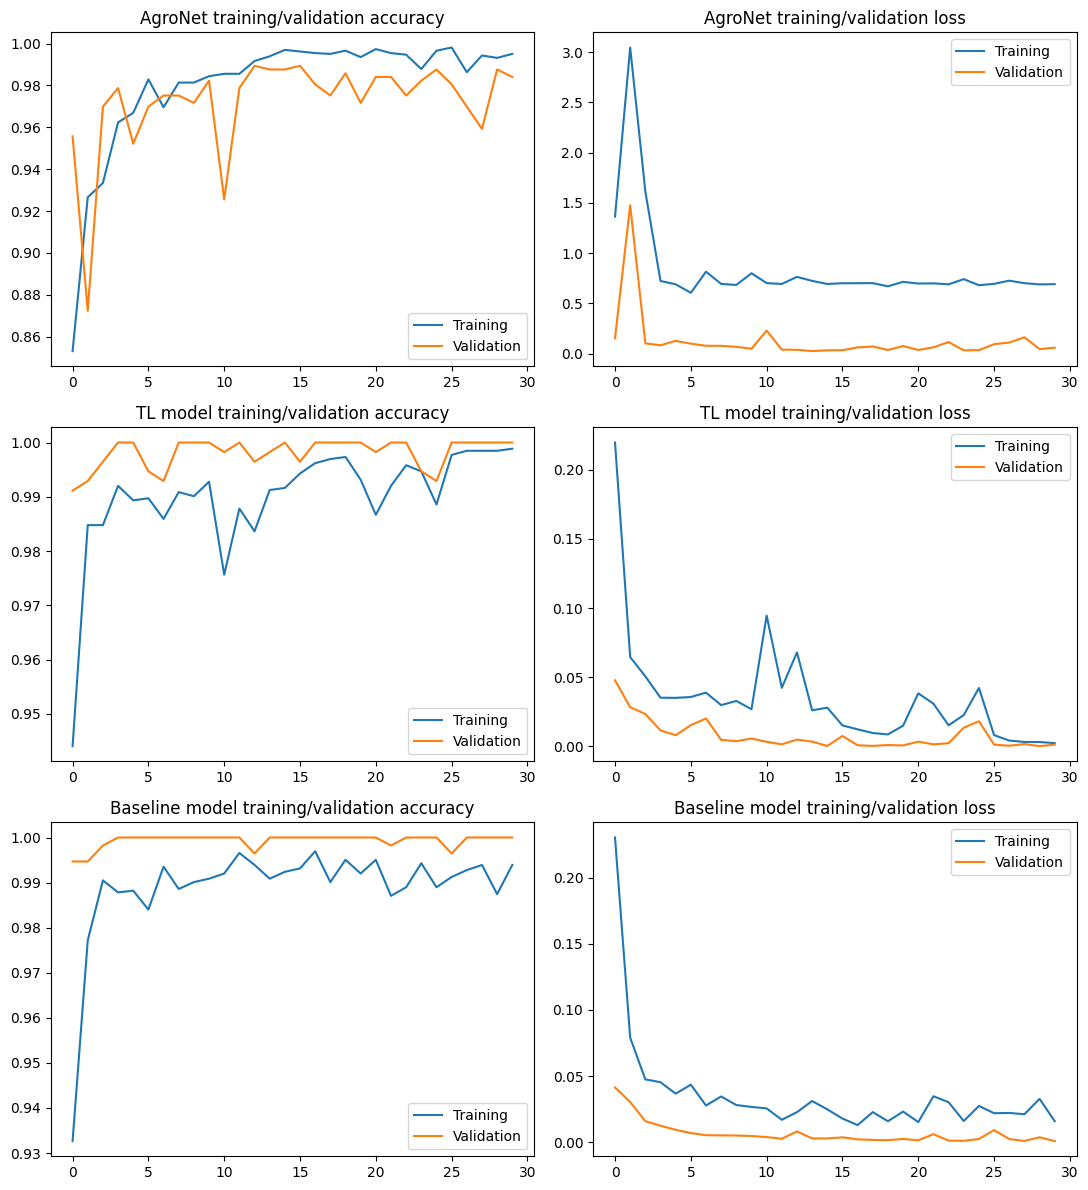

In [8]:

agronet  = AgroNet(num_classes=NUM_CLASSES, img_size=CONFIG["AGRONET_IMG_SIZE"],
                    domain_lambda=CONFIG["DOMAIN_ADV_LAMBDA"])
baseline = BaselineModel(num_classes=NUM_CLASSES)
tl_model = TLModel(num_classes=NUM_CLASSES)

hist_agronet  = train_source(agronet,  "agronet",  loaders_agronet,    CONFIG["EPOCHS_SOURCE"], CONFIG["LR"])
hist_baseline = train_source(baseline, "baseline", loaders_pretrained, CONFIG["EPOCHS_SOURCE"], CONFIG["LR"])
hist_tl       = train_source(tl_model, "tl",       loaders_pretrained, CONFIG["EPOCHS_SOURCE"], CONFIG["LR"])

fig, axes = plt.subplots(3, 2, figsize=(11, 12))
for row, (name, h) in enumerate([("AgroNet", hist_agronet), ("TL model", hist_tl), ("Baseline model", hist_baseline)]):
    axes[row, 0].plot(h["train_acc"], label="Training"); axes[row, 0].plot(h["val_acc"], label="Validation")
    axes[row, 0].set_title(f"{name} training/validation accuracy"); axes[row, 0].legend()
    axes[row, 1].plot(h["train_loss"], label="Training"); axes[row, 1].plot(h["val_loss"], label="Validation")
    axes[row, 1].set_title(f"{name} training/validation loss"); axes[row, 1].legend()
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/figure5_source_training_curves.png", dpi=150)
plt.show()



## 8. Source-domain evaluation (Figures 6–8)


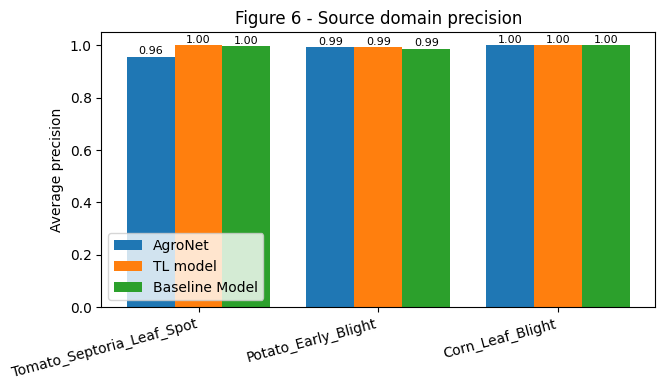

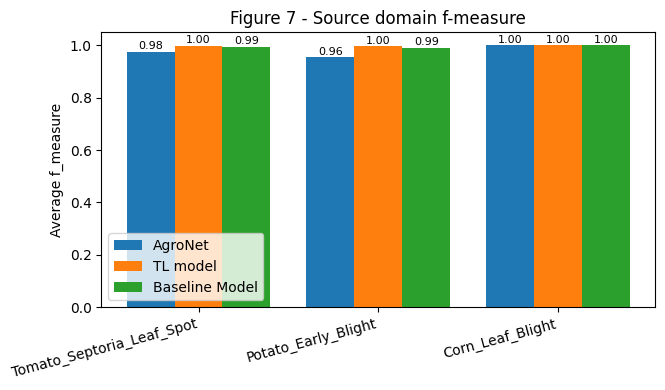

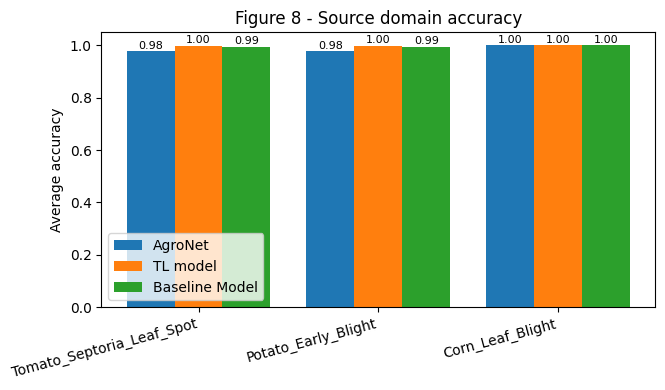

Source test accuracy -> AgroNet=0.9770  TL=0.9982  Baseline=0.9947


In [9]:

yt_a, yp_a = predict_all(agronet,  loaders_agronet["src_test"],    "agronet")
yt_t, yp_t = predict_all(tl_model, loaders_pretrained["src_test"], "tl")
yt_b, yp_b = predict_all(baseline, loaders_pretrained["src_test"], "baseline")

df_src_a = per_class_metrics(yt_a, yp_a, CLASSES)
df_src_t = per_class_metrics(yt_t, yp_t, CLASSES)
df_src_b = per_class_metrics(yt_b, yp_b, CLASSES)

src_models_dict = {"AgroNet": df_src_a, "TL model": df_src_t, "Baseline Model": df_src_b}
grouped_bar(src_models_dict, "precision", "Figure 6 - Source domain precision")
grouped_bar(src_models_dict, "f_measure", "Figure 7 - Source domain f-measure")
grouped_bar(src_models_dict, "accuracy",  "Figure 8 - Source domain accuracy")

src_test_acc_agronet  = accuracy_score(yt_a, yp_a)
src_test_acc_tl       = accuracy_score(yt_t, yp_t)
src_test_acc_baseline = accuracy_score(yt_b, yp_b)
print(f"Source test accuracy -> AgroNet={src_test_acc_agronet:.4f}  TL={src_test_acc_tl:.4f}  Baseline={src_test_acc_baseline:.4f}")



## 9. Fine-tune on the target retrain subset, then evaluate on `tgt_test` (Figures 9–11)

`tgt_test` here is built from the **exact same `LeafIndex` + split code** as your
MicroBrainNet-DA notebook — same images, same order, same held-out set — so the numbers below
sit directly next to your Part 6/Part 11 output.


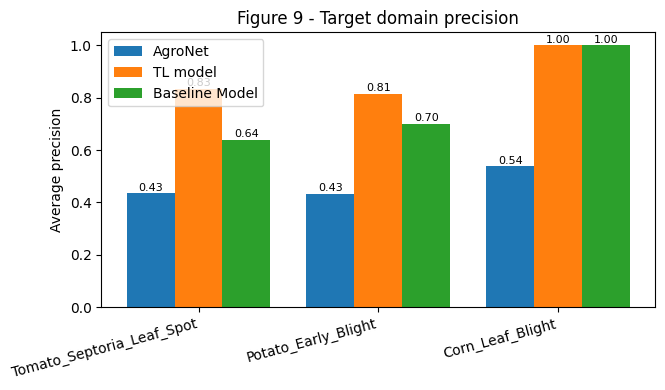

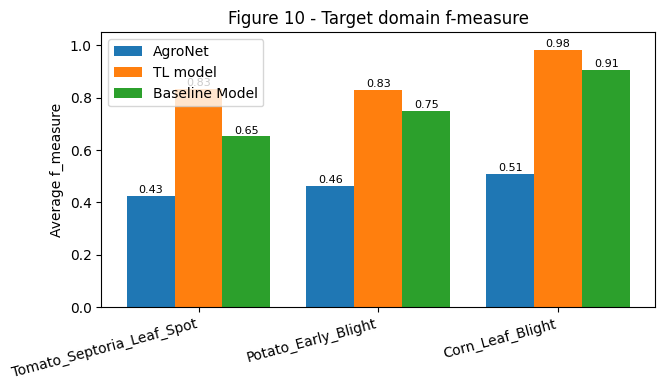

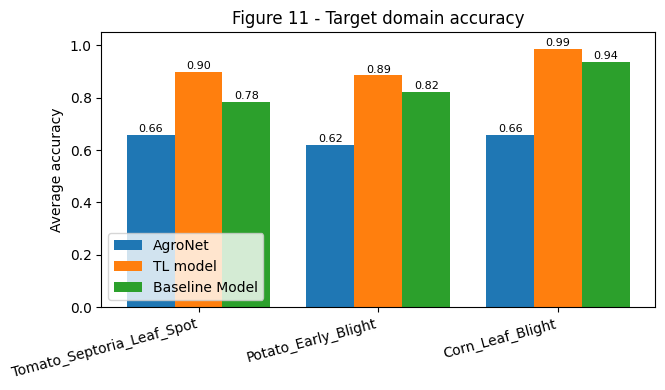

AgroNet    target-test acc = 0.4687  95% CI [0.3671, 0.5823]  (n=79)
TL model   target-test acc = 0.8851  95% CI [0.8101, 0.9494]  (n=79)
Baseline   target-test acc = 0.7710  95% CI [0.6709, 0.8608]  (n=79)


In [10]:

agronet_tgt  = finetune_on_target(copy.deepcopy(agronet),  "agronet",  loaders_agronet,    CONFIG["EPOCHS_TARGET"], CONFIG["LR"] * 0.5)
tl_tgt       = finetune_on_target(copy.deepcopy(tl_model), "tl",       loaders_pretrained, CONFIG["EPOCHS_TARGET"], CONFIG["LR"] * 0.5)
baseline_tgt = finetune_on_target(copy.deepcopy(baseline), "baseline", loaders_pretrained, CONFIG["EPOCHS_TARGET"], CONFIG["LR"] * 0.5)

yt_a2, yp_a2 = predict_all(agronet_tgt,  loaders_agronet["tgt_test"],    "agronet")
yt_t2, yp_t2 = predict_all(tl_tgt,       loaders_pretrained["tgt_test"], "tl")
yt_b2, yp_b2 = predict_all(baseline_tgt, loaders_pretrained["tgt_test"], "baseline")

df_tgt_a = per_class_metrics(yt_a2, yp_a2, CLASSES)
df_tgt_t = per_class_metrics(yt_t2, yp_t2, CLASSES)
df_tgt_b = per_class_metrics(yt_b2, yp_b2, CLASSES)

tgt_models_dict = {"AgroNet": df_tgt_a, "TL model": df_tgt_t, "Baseline Model": df_tgt_b}
grouped_bar(tgt_models_dict, "precision", "Figure 9 - Target domain precision")
grouped_bar(tgt_models_dict, "f_measure", "Figure 10 - Target domain f-measure")
grouped_bar(tgt_models_dict, "accuracy",  "Figure 11 - Target domain accuracy")

# Bootstrap 95% CI on target-test accuracy -- same protocol as your MicroBrainNet-DA notebook
ci_agronet  = bootstrap_ci(yt_a2, yp_a2)
ci_tl       = bootstrap_ci(yt_t2, yp_t2)
ci_baseline = bootstrap_ci(yt_b2, yp_b2)

for name, (mean, lo, hi) in [("AgroNet", ci_agronet), ("TL model", ci_tl), ("Baseline", ci_baseline)]:
    print(f"{name:10s} target-test acc = {mean:.4f}  95% CI [{lo:.4f}, {hi:.4f}]  (n={len(yt_a2)})")



## 10. Memory & energy usage (Table 2 style)

Two measurement modes are provided:

- **GPU (`torch.cuda.max_memory_allocated`)** — resets PyTorch's peak-memory counter right before
  training and reads it right after. This isolates *only* the tensors PyTorch actually allocated
  for that model's forward/backward passes — it is **not** inflated by Kaggle's baseline
  session memory (loaded libraries, cached images, kernel overhead), unlike a whole-process
  `psutil` reading. **Use this if `DEVICE.type == "cuda"`** (almost certainly true if training 5
  epochs finished in well under a minute, as in a typical Kaggle GPU session).
- **CPU (`tracemalloc`)** — a pure-Python fallback that also isolates the training call's own
  memory delta rather than the whole process's RSS.

If you previously saw near-identical memory numbers (~1550 MB) across all three models with the
old `psutil`-RSS version, that's the tell-tale sign the *process baseline* (not the model) was
being measured — the fix below reports the model-specific delta instead. Energy = elapsed
seconds × `ASSUMED_POWER_W`, same as before (and AgroNet legitimately taking ~4x longer than
Baseline/TL is expected and correct — it also runs a target-domain batch through the domain head
every iteration, roughly doubling the work per step).


In [11]:

def measure_memory_and_energy(train_fn, *args, **kwargs):
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats(DEVICE)
        t0 = time.time()
        result = train_fn(*args, **kwargs)
        torch.cuda.synchronize()
        elapsed = time.time() - t0
        peak_mem_mb = torch.cuda.max_memory_allocated(DEVICE) / (1024 ** 2)
        method = "cuda.max_memory_allocated"
    else:
        import tracemalloc
        tracemalloc.start()
        t0 = time.time()
        result = train_fn(*args, **kwargs)
        elapsed = time.time() - t0
        _, peak_bytes = tracemalloc.get_traced_memory()
        tracemalloc.stop()
        peak_mem_mb = peak_bytes / (1024 ** 2)
        method = "tracemalloc (CPU)"
    energy_j = elapsed * CONFIG["ASSUMED_POWER_W"]
    return result, {"memory_mb": round(peak_mem_mb, 1), "energy_j": round(energy_j, 1),
                     "seconds": round(elapsed, 1), "method": method}


_, stats_agronet  = measure_memory_and_energy(train_source, AgroNet(NUM_CLASSES, CONFIG["AGRONET_IMG_SIZE"]),
                                               "agronet", loaders_agronet, 5, CONFIG["LR"])
_, stats_baseline = measure_memory_and_energy(train_source, BaselineModel(NUM_CLASSES),
                                               "baseline", loaders_pretrained, 5, CONFIG["LR"])
_, stats_tl       = measure_memory_and_energy(train_source, TLModel(NUM_CLASSES),
                                               "tl", loaders_pretrained, 5, CONFIG["LR"])
# NOTE: measured over 5 epochs here (quick resource probe) -- scale seconds/energy_j by
# (CONFIG["EPOCHS_SOURCE"] / 5) if you want a full-run estimate matching the actual training above.
# GPU peak memory does NOT need this scaling -- it reflects per-batch/per-model footprint, not
# a cumulative total, so it stays valid regardless of how many epochs you actually trained for.

table2 = pd.DataFrame([
    {"Model": "AgroNet",        **stats_agronet},
    {"Model": "TL Model",       **stats_tl},
    {"Model": "Baseline Model", **stats_baseline},
])
print(table2)
table2.to_csv(f"{TABLES_DIR}/table2_memory_energy.csv", index=False)


[agronet] epoch 1/5 train_acc=0.876 val_acc=0.954
[agronet] epoch 5/5 train_acc=0.986 val_acc=0.986
[baseline] epoch 1/5 train_acc=0.948 val_acc=0.993
[baseline] epoch 5/5 train_acc=0.988 val_acc=1.000
[tl] epoch 1/5 train_acc=0.935 val_acc=0.991
[tl] epoch 5/5 train_acc=0.986 val_acc=0.998
            Model  memory_mb  energy_j  seconds                     method
0         AgroNet      310.7    2554.2    170.3  cuda.max_memory_allocated
1        TL Model      307.1     584.2     38.9  cuda.max_memory_allocated
2  Baseline Model      307.1     576.5     38.4  cuda.max_memory_allocated



## 10B. Model size / parameter count

Not in the paper's own tables, but needed for a fair size comparison against MicroBrainNet-DA's
`deploy_params` (Part 10A of your notebook). Reports, per model:

- **Total params** — every parameter in the model (backbone + head), fp32
- **Trainable params** — only those with `requires_grad=True` **at the point measured** (after
  target fine-tuning) — e.g. Baseline's backbone is fully frozen so only its head counts here,
  TL model has some unfrozen backbone layers from gradual fine-tuning, AgroNet is 100% trainable
  since it's trained from scratch
- **Size (MB, fp32)** — `total_params × 4 bytes`, the naive in-memory float32 footprint
- **Size (MB, ~int8)** — a rough `÷ 4` estimate of what an INT8-quantized version would take,
  for an apples-to-apples comparison against MicroBrainNet-DA's already-quantized
  `deploy_params`/TFLite size. This is only an estimate — it doesn't account for quantization
  overhead, per-layer scale/zero-point storage, or graph metadata the way an actual TFLite
  conversion would.


In [12]:

def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    size_fp32_mb = total * 4 / (1024 ** 2)
    size_int8_est_mb = total * 1 / (1024 ** 2)   # rough estimate, no quantization overhead modeled
    return total, trainable, size_fp32_mb, size_int8_est_mb


model_size_rows = []
for name, m in [("AgroNet", agronet_tgt), ("TL Model", tl_tgt), ("Baseline Model", baseline_tgt)]:
    total, trainable, size_fp32, size_int8 = count_params(m)
    model_size_rows.append({
        "Model": name,
        "Total params": total,
        "Trainable params (post target fine-tune)": trainable,
        "Size (MB, fp32)": round(size_fp32, 2),
        "Size (MB, ~int8 est.)": round(size_int8, 2),
    })

table_model_size = pd.DataFrame(model_size_rows)
print(table_model_size.to_string(index=False))
table_model_size.to_csv(f"{TABLES_DIR}/model_size.csv", index=False)


         Model  Total params  Trainable params (post target fine-tune)  Size (MB, fp32)  Size (MB, ~int8 est.)
       AgroNet       4259813                                   4259813            16.25                   4.06
      TL Model       2227715                                   1056323             8.50                   2.12
Baseline Model       2227715                                      3843             8.50                   2.12



## 11. Combined comparison — paper baselines vs. MicroBrainNet-DA v7

Paste in your MicroBrainNet-DA numbers from **its own Part 11 (Summary)** and, if you ran it,
**Part 7 (multi-seed mean ± std)** below. This builds one master table + bar chart with all four
methods on the identical `tgt_test` split, all reported with a 95% CI (or std across seeds).


         Model  Target-test acc   CI low  CI high  Source-test acc  Total params
       AgroNet         0.468686 0.367089 0.582278         0.976950       4259813
      TL model         0.885086 0.810127 0.949367         0.998227       2227715
Baseline model         0.770982 0.670886 0.860759         0.994681       2227715


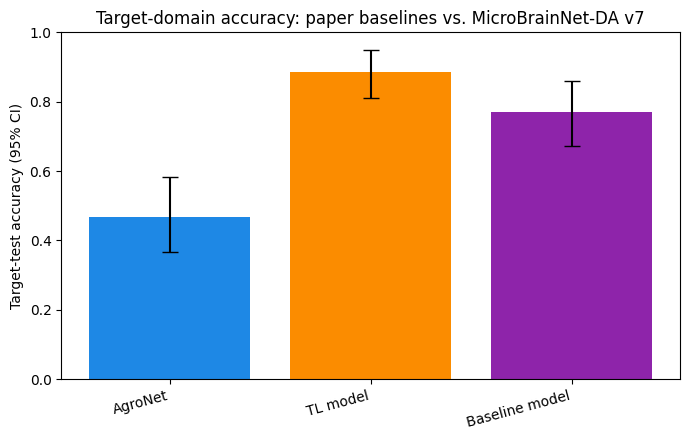

In [13]:

# ---- EDIT THIS with your MicroBrainNet-DA v7 output (Part 11 summary / Part 7 multi-seed) ----
microbrainnet_result = {
    "name": "MicroBrainNet-DA (v7)",
    "target_test_acc": None,   # e.g. 0.78  (tgt_acc from Part 11, or sdf.tgt_test.mean() from Part 7)
    "ci_lo": None,             # e.g. 0.69  (Part 6 bootstrap_ci, or seed std lower bound)
    "ci_hi": None,             # e.g. 0.86
    "source_test_acc": None,   # e.g. 0.99  (src_test_acc from Part 11)
    "params": None,            # e.g. 167000 (deploy_params from Part 10A)
}
# -----------------------------------------------------------------------------------------------

params_lookup = table_model_size.set_index("Model")["Total params"].to_dict()

comparison_rows = [
    {"Model": "AgroNet",        "Target-test acc": ci_agronet[0],  "CI low": ci_agronet[1],  "CI high": ci_agronet[2],  "Source-test acc": src_test_acc_agronet,  "Total params": params_lookup["AgroNet"]},
    {"Model": "TL model",       "Target-test acc": ci_tl[0],       "CI low": ci_tl[1],       "CI high": ci_tl[2],       "Source-test acc": src_test_acc_tl,       "Total params": params_lookup["TL Model"]},
    {"Model": "Baseline model", "Target-test acc": ci_baseline[0], "CI low": ci_baseline[1], "CI high": ci_baseline[2], "Source-test acc": src_test_acc_baseline, "Total params": params_lookup["Baseline Model"]},
]
if microbrainnet_result["target_test_acc"] is not None:
    comparison_rows.append({
        "Model": microbrainnet_result["name"],
        "Target-test acc": microbrainnet_result["target_test_acc"],
        "CI low": microbrainnet_result["ci_lo"],
        "CI high": microbrainnet_result["ci_hi"],
        "Source-test acc": microbrainnet_result["source_test_acc"],
        "Total params": microbrainnet_result["params"],
    })

final_df = pd.DataFrame(comparison_rows)
print(final_df.to_string(index=False))
final_df.to_csv(f"{TABLES_DIR}/final_comparison.csv", index=False)

# Bar chart with 95% CI error bars on target-test accuracy
fig, ax = plt.subplots(figsize=(7, 4.5))
means = final_df["Target-test acc"].values
lo = final_df["CI low"].values
hi = final_df["CI high"].values
yerr = np.vstack([means - lo, hi - means])
ax.bar(final_df["Model"], means, yerr=yerr, capsize=6,
       color=["#1E88E5", "#FB8C00", "#8E24AA", "#43A047"][:len(final_df)])
ax.set_ylabel("Target-test accuracy (95% CI)")
ax.set_ylim(0, 1.0)
ax.set_title("Target-domain accuracy: paper baselines vs. MicroBrainNet-DA v7")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/final_comparison.png", dpi=150)
plt.show()



## Caveats — read before quoting numbers from this notebook

1. **Identical splits require an identical environment.** `LeafIndex` relies on `os.walk`, whose
   traversal order can differ across filesystems/OSes even with the same `SEED`. If you run this
   notebook and your MicroBrainNet-DA notebook in the **same Kaggle session** (same dataset
   mounts), the resulting `tgt_test_idx` will match. If you run them separately and want to be
   certain, print `sorted(tgt_test_idx.img_paths)` in both notebooks and diff them once.
2. **This is a from-scratch reconstruction of the paper**, not its original (unpublished) code —
   built from Table 1 / Figure 4 / the method description in Sections 4.3 and 4.2/5.2. Treat these
   as a faithful, good-faith baseline implementation, not a literal reproduction.
3. **Epoch/LR choices for the paper baselines are not tuned** the way MicroBrainNet-DA's
   hyperparameters are (warmup, cosine schedule, discriminative LR, etc.) — if you want the
   comparison to be maximally fair to the baselines too, consider giving AgroNet/TL/Baseline a
   comparable hyperparameter search budget before quoting a head-to-head number.
4. Report the **bootstrap CI**, not the bare point estimate, for every model here — the target
   test set is small, exactly as your own notebook already flags.


## 12. Real INT8 quantization (AgroNet, TL model, Baseline) — same route as MicroBrainNet-DA

Everything above is unchanged. This section **adds** a real, measured INT8 export for the three models that were evaluated on `tgt_test`
(`agronet_tgt`, `tl_tgt`, `baseline_tgt` — i.e. the models *after* target fine-tuning). It replaces the old `params x 1 byte` estimate of Section 10B
with a measured `.tflite` file and a measured INT8 accuracy. Single run, no multi-seed.

**Route (identical to the MicroBrainNet-DA notebook, Part 10B — no ONNX):**
1. Rebuild each network natively in TF/Keras and copy the PyTorch weights across layer by layer (shape-checked by `set_weights`).
2. A **parity gate** compares Keras and PyTorch logits on real images before anything is quantized; a weight-copy bug aborts the export for that model.
3. `tf.lite.TFLiteConverter` with `Optimize.DEFAULT`, a representative dataset, `TFLITE_BUILTINS_INT8`, and int8 input and output (no float fallback can hide in the file).
4. The input normalization of each model is baked into the graph (`[-1,1]` for AgroNet, ImageNet mean/std for TL/Baseline), so the TFLite model takes raw [0,1] pixels.
5. Calibration = up to 400 **source-val** + all **target-val** images (validation splits only; `tgt_test` is never used for calibration).
6. The real TFLite interpreter is run on the 79 `tgt_test` images, with the input quantized by the model's own scale / zero-point.

Details that matter for correctness: the AgroNet `fc1` weight is permuted from PyTorch's (C,H,W) flatten order to Keras' (H,W,C) order; stride-2 3x3 convs use explicit symmetric
`ZeroPadding2D` (TF `same` pads asymmetrically); AgroNet's domain head is a training-only branch and is not exported (inference uses `domain_forward=False`, as in `predict_all`).

TensorFlow is imported only here, after all DataLoader work above, and is hidden from the GPU.

In [14]:
# ============================================================
# 12A: SETUP + RAW UINT8 ARRAYS + HELPERS
# ============================================================
import gc, traceback
from collections import Counter

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import tensorflow as tf
try:
    tf.config.set_visible_devices([], "GPU")     # TF is used for CPU export / INT8 eval only
except Exception as _e:
    print("note: could not hide GPUs from TensorFlow:", _e)
tf.get_logger().setLevel("ERROR")
print("TensorFlow:", tf.__version__)

MODELS_DIR = f"{OUTPUT_DIR}/models"
os.makedirs(MODELS_DIR, exist_ok=True)

CAL_N_SRC       = 400      # calibration: up to 400 source-VAL images + ALL target-VAL images
CAL_SEED        = 0
TFLITE_THREADS  = 4
PARITY_N        = 32
PARITY_FAIL_REL = 0.05     # abort a model's export if max|dlogit| > 5% of the largest |logit| (weight-copy bug)


def load_raw_arrays(idx_obj, img_size, name=""):
    # Same ops as make_transforms(..., train=False) minus ToTensor/Normalize. ToTensor is x/255, so uint8 is lossless.
    rs = transforms.Resize((img_size, img_size))
    arr = np.empty((len(idx_obj.img_paths), img_size, img_size, 3), np.uint8)
    for i, pth in enumerate(idx_obj.img_paths):
        arr[i] = np.asarray(rs(Image.open(pth).convert("RGB")), dtype=np.uint8)
    print(f"  raw[{img_size}px {name:8s}] {arr.shape}  {arr.nbytes/1024**2:6.1f} MB")
    return arr


RAW = {}
for _sz in sorted({CONFIG["AGRONET_IMG_SIZE"], CONFIG["PRETRAINED_IMG_SIZE"]}):
    RAW[_sz] = dict(
        src_val=load_raw_arrays(src_val_idx, _sz, "src_val"),
        tgt_val=load_raw_arrays(tgt_val_idx, _sz, "tgt_val"),
        tgt_test=load_raw_arrays(tgt_test_idx, _sz, "tgt_test"),
        tgt_test_labels=np.array(tgt_test_idx.labels),
    )


def make_calibration(img_size, n_src=CAL_N_SRC, seed=CAL_SEED):
    rng = np.random.RandomState(seed)
    pick = rng.permutation(len(RAW[img_size]["src_val"]))[:n_src]
    cal = np.concatenate([RAW[img_size]["src_val"][pick], RAW[img_size]["tgt_val"]], axis=0)
    return cal[rng.permutation(len(cal))]


@torch.no_grad()
def torch_logits_from_raw(fwd, arr_u8, mean, std, bs=32):
    mean_t = torch.tensor(mean).view(1, 3, 1, 1)
    std_t = torch.tensor(std).view(1, 3, 1, 1)
    outs = []
    for i in range(0, len(arr_u8), bs):
        x = torch.from_numpy(arr_u8[i:i + bs]).permute(0, 3, 1, 2).float() / 255.0
        outs.append(fwd((x - mean_t) / std_t).float())
    return torch.cat(outs).numpy()


print("calibration set per model: up to", CAL_N_SRC, "source-val +", len(tgt_val_idx.labels), "target-val images")

TensorFlow: 2.20.0
  raw[128px src_val ] (564, 128, 128, 3)    26.4 MB
  raw[128px tgt_val ] (79, 128, 128, 3)     3.7 MB
  raw[128px tgt_test] (79, 128, 128, 3)     3.7 MB
  raw[224px src_val ] (564, 224, 224, 3)    81.0 MB
  raw[224px tgt_val ] (79, 224, 224, 3)    11.3 MB
  raw[224px tgt_test] (79, 224, 224, 3)    11.3 MB
calibration set per model: up to 400 source-val + 79 target-val images


In [15]:
# ============================================================
# 12B: TORCH -> KERAS TRANSLATOR (weights copied layer by layer)
# ============================================================
L = tf.keras.layers
_uid = {"n": 0}

def _nm(prefix):
    _uid["n"] += 1
    return f"{prefix}_{_uid['n']}"

def _np(t):
    return t.detach().cpu().numpy().astype(np.float32)


def _conv(x, m, name):
    kh, kw = m.kernel_size
    assert kh == kw and tuple(m.dilation) == (1, 1), "only square, non-dilated convs are supported"
    k, s, pad, g = kh, m.stride[0], m.padding[0], m.groups
    assert pad in (0, k // 2), f"unsupported padding {pad} for k={k}"
    dw = g > 1
    if dw:
        assert g == m.in_channels == m.out_channels, "only depthwise grouped convs are supported"
    if s > 1 and pad > 0:                      # explicit symmetric pad, as PyTorch (TF 'same' is asymmetric)
        x = L.ZeroPadding2D(pad, name=_nm(name + "_pad"))(x)
        padding = "valid"
    else:
        padding = "same" if pad > 0 else "valid"
    use_bias = m.bias is not None
    W = _np(m.weight)
    if dw:
        layer = L.DepthwiseConv2D(k, strides=s, padding=padding, depth_multiplier=1, use_bias=use_bias, name=_nm(name))
        y = layer(x)
        ws = [W.transpose(2, 3, 0, 1)]         # (C,1,kh,kw) -> (kh,kw,C,1)
    else:
        layer = L.Conv2D(m.out_channels, k, strides=s, padding=padding, use_bias=use_bias, name=_nm(name))
        y = layer(x)
        ws = [W.transpose(2, 3, 1, 0)]         # (Cout,Cin,kh,kw) -> (kh,kw,Cin,Cout)
    if use_bias:
        ws.append(_np(m.bias))
    layer.set_weights(ws)
    return y


def _bn(x, m, name):
    layer = L.BatchNormalization(epsilon=m.eps, name=_nm(name))
    y = layer(x)
    layer.set_weights([_np(m.weight), _np(m.bias), _np(m.running_mean), _np(m.running_var)])
    return y


def _dense(x, W_out_in, b, name):
    layer = L.Dense(W_out_in.shape[0], name=_nm(name))
    y = layer(x)
    layer.set_weights([np.ascontiguousarray(W_out_in.T), np.ascontiguousarray(b)])
    return y


def _tr(x, m, name):
    # Generic translator for the module types inside torchvision's MobileNetV2 `features`.
    cn = m.__class__.__name__
    if isinstance(m, nn.Conv2d):
        return _conv(x, m, name)
    if isinstance(m, nn.BatchNorm2d):
        return _bn(x, m, name)
    if isinstance(m, nn.ReLU6):
        return L.ReLU(max_value=6.0, name=_nm(name))(x)
    if isinstance(m, nn.ReLU):
        return L.ReLU(name=_nm(name))(x)
    if isinstance(m, (nn.Dropout, nn.Identity)):
        return x
    if cn == "InvertedResidual":
        y = _tr(x, m.conv, name)
        return L.Add(name=_nm(name + "_res"))([x, y]) if m.use_res_connect else y
    if isinstance(m, nn.Sequential):
        for i, c in enumerate(m):
            x = _tr(x, c, f"{name}_{i}")
        return x
    raise NotImplementedError(f"no Keras translation for {cn}")


def _input_block(img_size, mean, std):
    # Raw RGB in [0,1] -> (x - mean) / std, baked into the graph.
    inp = L.Input(shape=(img_size, img_size, 3), batch_size=1, name="input")
    sc = (1.0 / np.array(std, np.float32)).astype(np.float32)
    of = (-np.array(mean, np.float32) * sc).astype(np.float32)
    return inp, L.Lambda(lambda t: t * sc + of, name="input_norm")(inp)


def build_keras_agronet(tm, img_size, mean, std):
    # AgroNet inference path = TeaNet backbone + task head (domain head is training-only).
    _uid["n"] = 0
    inp, x = _input_block(img_size, mean, std)
    bb = tm.backbone
    for i, conv in enumerate([bb.conv1, bb.conv2, bb.conv3]):
        x = _conv(x, conv, f"conv{i+1}")
        x = L.ReLU(name=_nm(f"relu{i+1}"))(x)
        x = L.MaxPooling2D(2, name=_nm(f"pool{i+1}"))(x)
    x = L.Flatten(name="flatten")(x)                                   # Keras flattens (H,W,C)
    c, hw = bb.conv3.out_channels, img_size // 8
    W1 = _np(bb.fc1.weight).reshape(bb.fc1.out_features, c, hw, hw).transpose(0, 2, 3, 1).reshape(bb.fc1.out_features, -1)
    x = L.ReLU(name=_nm("relu_fc1"))(_dense(x, W1, _np(bb.fc1.bias), "fc1"))
    x = L.ReLU(name=_nm("relu_fc2"))(_dense(x, _np(bb.fc2.weight), _np(bb.fc2.bias), "fc2"))
    out = _dense(x, _np(tm.task_head.weight), _np(tm.task_head.bias), "task_head")
    return tf.keras.Model(inp, out, name="AgroNet_deploy")


def build_keras_mnv2(tm, img_size, mean, std):
    # Baseline / TL: MobileNetV2 features -> global average pool -> task FC.
    _uid["n"] = 0
    inp, x = _input_block(img_size, mean, std)
    x = _tr(x, tm.backbone.features, "features")
    x = L.GlobalAveragePooling2D(name="gap")(x)
    out = _dense(x, _np(tm.task_head.weight), _np(tm.task_head.bias), "task_head")
    return tf.keras.Model(inp, out, name="MobileNetV2_deploy")


print("Keras translator ready.")

Keras translator ready.


In [16]:
# ============================================================
# 12C: TFLITE CONVERSION (FP32 + full INT8), INTERPRETER EVALUATION, AUDIT
# ============================================================

def _make_rep_gen(cal_u8):
    def gen():
        for i in range(cal_u8.shape[0]):
            yield [cal_u8[i:i + 1].astype(np.float32) / 255.0]       # model input is raw [0,1]
    return gen


def _convert(km, cal_u8=None):
    conv = tf.lite.TFLiteConverter.from_keras_model(km)
    if cal_u8 is not None:                                           # identical settings to the MicroBrainNet-DA notebook
        conv.optimizations = [tf.lite.Optimize.DEFAULT]
        conv.representative_dataset = _make_rep_gen(cal_u8)
        conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
        conv.inference_input_type = tf.int8
        conv.inference_output_type = tf.int8
    return conv.convert()


def tflite_logits(model_bytes, arr_u8, int8, threads=TFLITE_THREADS):
    # REAL TFLite interpreter. INT8: input quantized with the model's own scale/zero-point, int8 output dequantized.
    it = tf.lite.Interpreter(model_content=model_bytes, num_threads=threads)
    it.allocate_tensors()
    ind, outd = it.get_input_details()[0], it.get_output_details()[0]
    (s_i, z_i), (s_o, z_o) = ind["quantization"], outd["quantization"]
    if int8:
        assert ind["dtype"] == np.int8 and outd["dtype"] == np.int8, "model I/O is not int8"
    out = np.zeros((len(arr_u8), outd["shape"][-1]), np.float32)
    for i in range(len(arr_u8)):
        a = arr_u8[i:i + 1].astype(np.float32) / 255.0
        if int8:
            a = np.clip(np.round(a / s_i + z_i), -128, 127).astype(np.int8)
        it.set_tensor(ind["index"], a)
        it.invoke()
        o = it.get_tensor(outd["index"])[0]
        out[i] = (o.astype(np.float32) - z_o) * s_o if int8 else o
    return out


def audit_tflite(model_bytes, label):
    it = tf.lite.Interpreter(model_content=model_bytes)
    it.allocate_tensors()
    ind, outd = it.get_input_details()[0], it.get_output_details()[0]
    cnt, nbytes, big_float = Counter(), Counter(), []
    for d in it.get_tensor_details():
        dt = np.dtype(d["dtype"])
        n = int(np.prod(d["shape"])) if len(d["shape"]) else 1
        cnt[dt.name] += 1
        nbytes[dt.name] += n * dt.itemsize
        if dt == np.float32 and n >= 1000:
            big_float.append((d["name"][:60], n))
    print(f"\n--- INT8 audit: {label} ---")
    print(f"file size        : {len(model_bytes)/1024:.1f} KB")
    print(f"input            : dtype={np.dtype(ind['dtype']).name} shape={list(ind['shape'])} (scale, zero_point)={ind['quantization']}")
    print(f"output           : dtype={np.dtype(outd['dtype']).name} shape={list(outd['shape'])} (scale, zero_point)={outd['quantization']}")
    print(f"tensors by dtype : {dict(cnt)}")
    print("float32 tensors >=1000 elements:", big_float[:6] if big_float else "none (no un-quantized weights / activations)")
    try:
        ops = Counter(d["op_name"] for d in it._get_ops_details())
        print(f"ops ({sum(ops.values())} nodes): {dict(sorted(ops.items()))}")
        bad = [o for o in ops if "flex" in o.lower() or "custom" in o.lower()]
        print("Flex/custom ops  :", bad if bad else "none")
    except Exception as e:
        print("op list not available in this TF build:", e)


def export_model_int8(spec):
    # spec: name, model (PyTorch, trained), kind, size, mean, std
    name, size = spec["name"], spec["size"]
    tm = copy.deepcopy(spec["model"]).cpu().eval()
    if spec["kind"] == "agronet":
        fwd = lambda x, m=tm: m(x, domain_forward=False)
        builder = build_keras_agronet
    else:
        fwd = lambda x, m=tm: m(x)
        builder = build_keras_mnv2

    tf.keras.backend.clear_session(); gc.collect()
    t0 = time.time()
    km = builder(tm, size, spec["mean"], spec["std"])               # translation bugs are NOT caught: they must be loud
    arr = RAW[size]["tgt_val"][:PARITY_N]
    ref = torch_logits_from_raw(fwd, arr, spec["mean"], spec["std"])
    got = np.concatenate([km(arr[i:i + 1].astype(np.float32) / 255.0, training=False).numpy() for i in range(len(arr))], 0)
    mad = float(np.abs(ref - got).max()); rel = mad / (float(np.abs(ref).max()) + 1e-6)
    agree = float((ref.argmax(1) == got.argmax(1)).mean())
    print(f"  [{name}] Keras params {km.count_params():,} | parity vs PyTorch: max|dlogit|={mad:.2e} (rel {rel:.2e}), "
          f"top-1 agreement {agree*100:.1f}%")
    if rel > PARITY_FAIL_REL:
        raise RuntimeError(f"{name}: Keras model does not reproduce the PyTorch model (rel diff {rel:.3f}) - "
                           f"weight copy / layout bug, refusing to quantize.")

    cal = make_calibration(size)
    fp32_bytes = _convert(km, None)
    int8_bytes = _convert(km, cal)
    print(f"  [{name}] converted in {time.time()-t0:.0f}s | calibration images: {len(cal)} | "
          f"FP32 tflite {len(fp32_bytes)/1024:.1f} KB | INT8 tflite {len(int8_bytes)/1024:.1f} KB")
    return dict(fp32_bytes=fp32_bytes, int8_bytes=int8_bytes, parity_rel=rel, parity_agree=agree)

print("TFLite export / evaluation helpers ready.")

TFLite export / evaluation helpers ready.


In [17]:
# ============================================================
# 12D: EXPORT + EVALUATE ALL THREE MODELS (single run)
# ============================================================
SPECS = [
    dict(name="AgroNet",        model=agronet_tgt,  kind="agronet", size=CONFIG["AGRONET_IMG_SIZE"],
         mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5], yt=yt_a2, yp=yp_a2, ci=ci_agronet, tag="agronet"),
    dict(name="TL model",       model=tl_tgt,       kind="mnv2",    size=CONFIG["PRETRAINED_IMG_SIZE"],
         mean=IMAGENET_MEAN, std=IMAGENET_STD, yt=yt_t2, yp=yp_t2, ci=ci_tl, tag="tl"),
    dict(name="Baseline model", model=baseline_tgt, kind="mnv2",    size=CONFIG["PRETRAINED_IMG_SIZE"],
         mean=IMAGENET_MEAN, std=IMAGENET_STD, yt=yt_b2, yp=yp_b2, ci=ci_baseline, tag="baseline"),
]

quant_rows = []
for sp in SPECS:
    print(f"\n{'#'*90}\n# {sp['name']}  ({sp['size']}px)\n{'#'*90}")
    torch.save(sp["model"].state_dict(), f"{MODELS_DIR}/{sp['tag']}_after_target_finetune.pth")   # never lose a trained model
    row = dict(Model=sp["name"], int8_ok=False)
    try:
        res = export_model_int8(sp)
        with open(f"{MODELS_DIR}/{sp['tag']}_fp32.tflite", "wb") as f: f.write(res["fp32_bytes"])
        with open(f"{MODELS_DIR}/{sp['tag']}_int8.tflite", "wb") as f: f.write(res["int8_bytes"])

        yt = RAW[sp["size"]]["tgt_test_labels"]
        assert np.array_equal(yt, sp["yt"]), "raw target-test order differs from the loader order"
        lg_f = tflite_logits(res["fp32_bytes"], RAW[sp["size"]]["tgt_test"], False)
        lg_i = tflite_logits(res["int8_bytes"], RAW[sp["size"]]["tgt_test"], True)
        pf, pi = lg_f.argmax(1), lg_i.argmax(1)
        ci_i = bootstrap_ci(yt, pi)
        acc_fp32, acc_tfl, acc_i8 = accuracy_score(yt, sp["yp"]), accuracy_score(yt, pf), accuracy_score(yt, pi)
        row.update(int8_ok=True,
                   fp32_tgt_acc=acc_fp32, fp32_ci_lo=sp["ci"][1], fp32_ci_hi=sp["ci"][2],
                   tflite_fp32_tgt_acc=acc_tfl,
                   int8_tgt_acc=acc_i8, int8_ci_lo=ci_i[1], int8_ci_hi=ci_i[2],
                   int8_f1_weighted=f1_score(yt, pi, average="weighted"),
                   acc_drop_pts=(acc_fp32 - acc_i8) * 100,
                   agree_with_fp32=float((pi == sp["yp"]).mean()),
                   tflite_fp32_kb=len(res["fp32_bytes"]) / 1024, int8_kb=len(res["int8_bytes"]) / 1024,
                   parity_rel=res["parity_rel"])
        pd.DataFrame({"path": tgt_test_idx.img_paths, "label": yt, "pred_fp32_torch": sp["yp"],
                      "pred_tflite_fp32": pf, "pred_int8": pi}).to_csv(
            f"{TABLES_DIR}/{sp['tag']}_tgt_test_predictions_int8.csv", index=False)
        print(f"  [{sp['name']}] target-test  FP32(PyTorch)={acc_fp32:.4f}  FP32(TFLite)={acc_tfl:.4f}  "
              f"INT8(TFLite)={acc_i8:.4f}  95% CI [{ci_i[1]:.4f}, {ci_i[2]:.4f}]")
        print(f"  [{sp['name']}] drop FP32->INT8 = {row['acc_drop_pts']:+.2f} pts | INT8-vs-FP32 agreement = "
              f"{row['agree_with_fp32']*100:.1f}% | INT8 file = {row['int8_kb']:.1f} KB")
        audit_tflite(res["int8_bytes"], f"{sp['name']} ({sp['tag']}_int8.tflite)")
        del res
    except Exception as e:                            # one failing model must not stop the others
        print(f"  !! INT8 export FAILED for {sp['name']}: {type(e).__name__}: {e}")
        traceback.print_exc()
    quant_rows.append(row)
    gc.collect()

quant_df = pd.DataFrame(quant_rows)
quant_df.to_csv(f"{TABLES_DIR}/quantization_results.csv", index=False)
print("\n" + "=" * 100)
cols = [c for c in ["Model", "int8_ok", "fp32_tgt_acc", "tflite_fp32_tgt_acc", "int8_tgt_acc", "acc_drop_pts",
                    "agree_with_fp32", "tflite_fp32_kb", "int8_kb"] if c in quant_df.columns]
print(quant_df[cols].round(4).to_string(index=False))


##########################################################################################
# AgroNet  (128px)
##########################################################################################
  [AgroNet] Keras params 4,251,427 | parity vs PyTorch: max|dlogit|=3.81e-06 (rel 4.44e-07), top-1 agreement 100.0%
Saved artifact at '/tmp/tmp8_l_74nd'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(1, 128, 128, 3), dtype=tf.float32, name='input')
Output Type:
  TensorSpec(shape=(1, 3), dtype=tf.float32, name=None)
Captures:
  133341279129232: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133341279130192: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133341279129808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133341279126160: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133341279130000: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133341279130960: TensorSpec(shape=(), dtype=tf.resource, na

W0000 00:00:1792266451.951138      23 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1792266451.951174      23 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1792266451.960132      23 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled


Saved artifact at '/tmp/tmppq869ytx'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(1, 128, 128, 3), dtype=tf.float32, name='input')
Output Type:
  TensorSpec(shape=(1, 3), dtype=tf.float32, name=None)
Captures:
  133341279129232: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133341279130192: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133341279129808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133341279126160: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133341279130000: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133341279130960: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133341279130768: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133341279131344: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133341279129616: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133341279132112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133341279132496: TensorSpec

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:863: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1792266453.290492      23 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1792266453.290544      23 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
fully_quantize: 0, inference_type: 6, input_inference_type: INT8, output_inference_type: INT8
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


  [AgroNet] converted in 9s | calibration images: 479 | FP32 tflite 16611.5 KB | INT8 tflite 4170.1 KB
  [AgroNet] target-test  FP32(PyTorch)=0.4684  FP32(TFLite)=0.4684  INT8(TFLite)=0.4430  95% CI [0.3418, 0.5570]
  [AgroNet] drop FP32->INT8 = +2.53 pts | INT8-vs-FP32 agreement = 97.5% | INT8 file = 4170.1 KB

--- INT8 audit: AgroNet (agronet_int8.tflite) ---
file size        : 4170.1 KB
input            : dtype=int8 shape=[np.int32(1), np.int32(128), np.int32(128), np.int32(3)] (scale, zero_point)=(0.003921568859368563, -128)
output           : dtype=int8 shape=[np.int32(1), np.int32(3)] (scale, zero_point)=(0.12929365038871765, -2)
tensors by dtype : {'int8': 21, 'int32': 7}
float32 tensors >=1000 elements: none (no un-quantized weights / activations)
ops (13 nodes): {'ADD': 1, 'CONV_2D': 3, 'DELEGATE': 1, 'FULLY_CONNECTED': 3, 'MAX_POOL_2D': 3, 'MUL': 1, 'RESHAPE': 1}
Flex/custom ops  : none


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


... (9 outputs left out)

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:863: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1792266566.694025      23 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1792266566.694054      23 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
fully_quantize: 0, inference_type: 6, input_inference_type: INT8, output_inference_type: INT8
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


  [Baseline model] converted in 79s | calibration images: 479 | FP32 tflite 8663.7 KB | INT8 tflite 2641.9 KB
  [Baseline model] target-test  FP32(PyTorch)=0.7722  FP32(TFLite)=0.7722  INT8(TFLite)=0.7722  95% CI [0.6709, 0.8608]
  [Baseline model] drop FP32->INT8 = +0.00 pts | INT8-vs-FP32 agreement = 94.9% | INT8 file = 2641.9 KB

--- INT8 audit: Baseline model (baseline_int8.tflite) ---
file size        : 2641.9 KB
input            : dtype=int8 shape=[np.int32(1), np.int32(224), np.int32(224), np.int32(3)] (scale, zero_point)=(0.003921568859368563, -128)
output           : dtype=int8 shape=[np.int32(1), np.int32(3)] (scale, zero_point)=(0.12863752245903015, 23)
tensors by dtype : {'int8': 127, 'int32': 55}
float32 tensors >=1000 elements: none (no un-quantized weights / activations)
ops (72 nodes): {'ADD': 11, 'CONV_2D': 35, 'DELEGATE': 1, 'DEPTHWISE_CONV_2D': 17, 'FULLY_CONNECTED': 1, 'MEAN': 1, 'MUL': 1, 'PAD': 5}
Flex/custom ops  : none


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)



         Model  int8_ok  fp32_tgt_acc  tflite_fp32_tgt_acc  int8_tgt_acc  acc_drop_pts  agree_with_fp32  tflite_fp32_kb   int8_kb
       AgroNet     True        0.4684               0.4684        0.4430        2.5316           0.9747      16611.5312 4170.1328
      TL model     True        0.8861               0.8861        0.8734        1.2658           0.9620       8663.7266 2641.9297
Baseline model     True        0.7722               0.7722        0.7722        0.0000           0.9494       8663.7266 2641.9297


### 12E. Measured INT8 size vs. the old estimate, and the updated comparison

The size column of Section 10B (`params x 1 byte`) was an estimate. The table below puts the **measured** `.tflite` size next to it, and extends the Section 11 comparison with the INT8 accuracy.
The MicroBrainNet-DA row is filled from its own notebook (INT8 TFLite 245.6 KB, 167,131 parameters, 75.95 % target accuracy of the exported INT8 model, bootstrap CI [0.6582, 0.8481]) — **edit the constants if you re-run it**.

         Model  Total params  Size (MB, fp32)  Size (MB, ~int8 est.)  FP32 .tflite (KB, measured)  INT8 .tflite (KB, measured)  INT8 measured / est.
       AgroNet       4259813            16.25                   4.06                      16611.5                       4170.1                  1.00
      TL model       2227715             8.50                   2.12                       8663.7                       2641.9                  1.22
Baseline model       2227715             8.50                   2.12                       8663.7                       2641.9                  1.22

                                Model  FP32 target acc  INT8 target acc  INT8 CI low  INT8 CI high  Drop (pts)  INT8 .tflite (KB)  Total params
                              AgroNet           0.4684           0.4430       0.3418        0.5570      2.5316          4170.1328       4259813
                             TL model           0.8861           0.8734       0.7975        0.9367      1.2658     

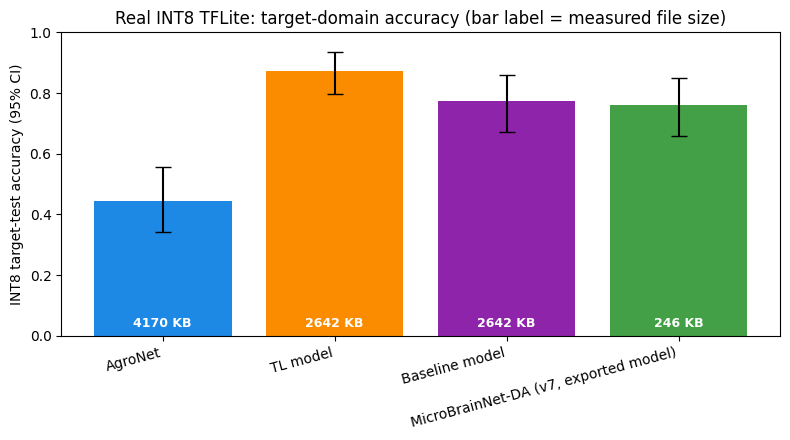

In [18]:
# ============================================================
# 12E: MEASURED SIZE vs ESTIMATE + UPDATED COMPARISON TABLE / PLOT
# ============================================================
ok = quant_df[quant_df["int8_ok"].astype(bool)].copy() if "int8_ok" in quant_df else quant_df.iloc[0:0]

# ---- size: measured vs. the old estimate ----
if len(ok):
    est = table_model_size.set_index("Model")
    name_map = {"AgroNet": "AgroNet", "TL model": "TL Model", "Baseline model": "Baseline Model"}
    size_rows = []
    for _, r in ok.iterrows():
        e = est.loc[name_map[r.Model]]
        size_rows.append({"Model": r.Model,
                          "Total params": int(e["Total params"]),
                          "Size (MB, fp32)": e["Size (MB, fp32)"],
                          "Size (MB, ~int8 est.)": e["Size (MB, ~int8 est.)"],
                          "FP32 .tflite (KB, measured)": round(r.tflite_fp32_kb, 1),
                          "INT8 .tflite (KB, measured)": round(r.int8_kb, 1),
                          "INT8 measured / est.": round((r.int8_kb / 1024) / e["Size (MB, ~int8 est.)"], 2)})
    size_cmp = pd.DataFrame(size_rows)
    print(size_cmp.to_string(index=False))
    size_cmp.to_csv(f"{TABLES_DIR}/model_size_measured_int8.csv", index=False)
else:
    print("No INT8 model was exported: no measured size exists (the old estimate is NOT substituted).")

# ---- updated comparison with INT8 ----
# EDIT if you re-run MicroBrainNet-DA (values from its Part 10C output / Part 11 summary)
IM = dict(name="MicroBrainNet-DA (v7, exported model)", fp32_acc=0.7595, int8_acc=0.7595, ci_lo=0.6582, ci_hi=0.8481,
          int8_kb=245.6, params=167_131)

rows = []
for _, r in ok.iterrows():
    rows.append({"Model": r.Model, "FP32 target acc": r.fp32_tgt_acc, "INT8 target acc": r.int8_tgt_acc,
                 "INT8 CI low": r.int8_ci_lo, "INT8 CI high": r.int8_ci_hi, "Drop (pts)": r.acc_drop_pts,
                 "INT8 .tflite (KB)": r.int8_kb, "Total params": params_lookup[name_map[r.Model]]})
rows.append({"Model": IM["name"], "FP32 target acc": IM["fp32_acc"], "INT8 target acc": IM["int8_acc"],
             "INT8 CI low": IM["ci_lo"], "INT8 CI high": IM["ci_hi"], "Drop (pts)": (IM["fp32_acc"] - IM["int8_acc"]) * 100,
             "INT8 .tflite (KB)": IM["int8_kb"], "Total params": IM["params"]})
final_int8_df = pd.DataFrame(rows)
print("\n" + final_int8_df.round(4).to_string(index=False))
final_int8_df.to_csv(f"{TABLES_DIR}/final_comparison_int8.csv", index=False)

# ---- plot: INT8 target accuracy with 95% CI ----
fig, ax = plt.subplots(figsize=(8, 4.5))
m_ = final_int8_df["INT8 target acc"].values
yerr = np.vstack([m_ - final_int8_df["INT8 CI low"].values, final_int8_df["INT8 CI high"].values - m_])
ax.bar(final_int8_df["Model"], m_, yerr=yerr, capsize=6, color=["#1E88E5", "#FB8C00", "#8E24AA", "#43A047"][:len(final_int8_df)])
for x_, v_, kb_ in zip(range(len(m_)), m_, final_int8_df["INT8 .tflite (KB)"].values):
    ax.text(x_, 0.03, f"{kb_:.0f} KB", ha="center", color="white", fontsize=9, fontweight="bold")
ax.set_ylabel("INT8 target-test accuracy (95% CI)")
ax.set_ylim(0, 1.0)
ax.set_title("Real INT8 TFLite: target-domain accuracy (bar label = measured file size)")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/final_comparison_int8.png", dpi=150)
plt.show()

## Caveats for the INT8 section

1. **Same quantization method as MicroBrainNet-DA, so the numbers are comparable.** Native TF/Keras rebuild -> `tf.lite.TFLiteConverter`, full-integer post-training quantization
   (per-channel int8 conv weights, per-tensor int8 activations, int8 input/output, `TFLITE_BUILTINS_INT8`), calibration on source-val + target-val images. No ONNX.
2. **PTQ, not QAT.** A small FP32 -> INT8 drop is expected; it is printed per model, together with the INT8-vs-FP32 prediction agreement and per-image predictions in `tables/*_tgt_test_predictions_int8.csv`.
3. **What is quantized.** The models after target fine-tuning, in their inference form: AgroNet = TeaNet backbone + task head (the domain-adversarial head is training-only and not exported); TL / Baseline = MobileNetV2 features + global pooling + task FC.
4. **Sizes are now measured `.tflite` files.** The Section 10B `~int8 est.` column is kept for reference; the table in 12E shows how far the estimate was from the real file (graph metadata, scales / zero-points and int32 biases are included in the real file).
5. **Size is not a like-for-like budget comparison.** AgroNet's `fc1` alone has 16384 x 256 weights, and MobileNetV2-based models are several MB in INT8, whereas MicroBrainNet-DA is 245.6 KB. Compare accuracy per byte, not "fits the same MCU".
6. **Single run.** As requested there is no multi-seed here, so there is no std. With 79 target-test images, 1 image = 1.27 accuracy points: a FP32 -> INT8 difference of one or two images is within noise. Use the saved per-image predictions for a paired comparison.
7. **Calibration never touches `tgt_test`.** It uses 400 source-val and all target-val images (labels unused), exactly the recipe of the MicroBrainNet-DA export.